In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


# Titanic Survival Prediction
## Phase 01 — Data Understanding & EDA

### Project Objective
Predict passenger survival using machine learning.

**Competition:** Titanic - Machine Learning from Disaster

**Problem Type:** Binary Classification

**Evaluation Metric:** Accuracy

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [3]:
import pandas as pd
import numpy as np

train = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
test = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")

print("Training Data:", train.shape)
print("Testing Data:", test.shape)

display(train.head())

Training Data: (891, 12)
Testing Data: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Data Understanding

### 1.1 Dataset Structure

Examine the dataset dimensions, data types,
missing values, and descriptive statistics.

In [4]:
# Dataset information
train.info()

# Missing values
display(train.isnull().sum())

# Descriptive statistics
display(train.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


### 1.2 Initial Data Quality & Statistical Insights

**Missing Values**
- `Cabin` has approximately 77.1% missing values, making direct use challenging. However, cabin availability may provide useful information.
- `Age` contains 19.9% missing values and requires an appropriate imputation strategy.
- `Embarked` has only two missing values.

**Target Distribution**
- Approximately 38.4% of passengers survived, while 61.6% did not.
- The target distribution is moderately imbalanced, making stratified validation worth considering.

**Numerical Features**
- The median passenger age is 28 years, with an average of approximately 29.7 years.
- `Fare` shows evidence of positive skewness, with its mean substantially exceeding its median.

**Categorical Features**
- Male passengers account for approximately 64.8% of the training dataset.
- Third-class passengers represent at least half of the observations.
- Southampton (`S`) is the most frequent embarkation port.

**Next Steps**

Further exploratory analysis is needed to examine relationships between passenger characteristics and survival outcomes before selecting features and training predictive models.

## 2. Exploratory Data Analysis (EDA)
### 2.0 Target Variable Distribution

We visualize the distribution of the target variable
to understand class balance before exploring
relationships between passenger features and survival.

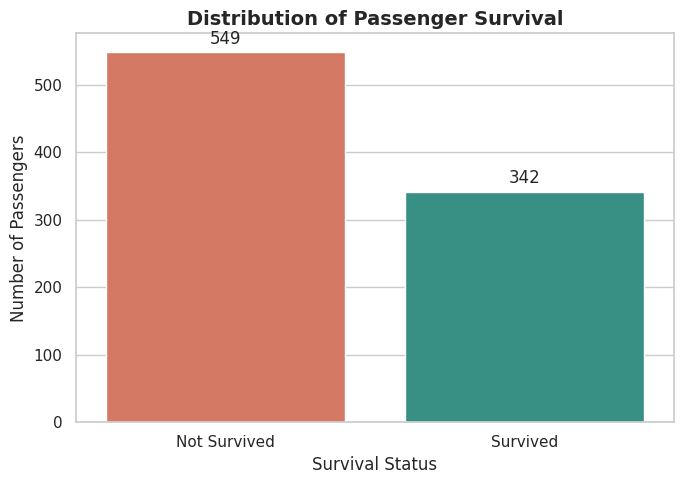

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(
    data=train,
    x="Survived",
    hue="Survived",
    palette=["#E76F51", "#2A9D8F"],
    legend=False,
    ax=ax
)

ax.set_title(
    "Distribution of Passenger Survival",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Survival Status")
ax.set_ylabel("Number of Passengers")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not Survived", "Survived"])

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

#### Key Insights — Target Distribution

- Of the 891 passengers in the training dataset, 549 (61.62%) did not survive, while 342 (38.38%) survived.
- The target variable exhibits moderate class imbalance, with non-survivors representing the majority class.
- Stratified sampling is appropriate for preserving class proportions during model evaluation.
- Accuracy should be interpreted alongside additional classification metrics to provide a more comprehensive assessment of model performance.

In [6]:
survival_by_sex = (
    train.groupby("Sex")["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival_Rate"
    })
)

survival_by_sex["Survival_Rate"] *= 100

display(survival_by_sex.round(2))

,Passengers,Survivors,Survival_Rate
Sex,,,
female,314,233,74.20
male,577,109,18.89


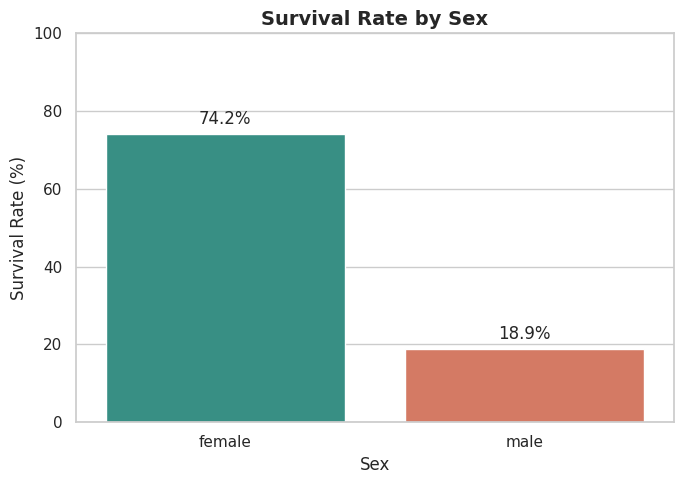

In [7]:
# Calculate survival rates by sex
sex_survival = (
    train.groupby("Sex")["Survived"]
    .mean()
    .mul(100)
    .reindex(["female", "male"])
)

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    x=sex_survival.index,
    y=sex_survival.values,
    hue=sex_survival.index,
    palette=["#2A9D8F", "#E76F51"],
    legend=False,
    ax=ax
)

ax.set_title(
    "Survival Rate by Sex",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Sex")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

#### Visualization Insights — Survival Rate by Sex

- Female passengers had a substantially higher survival rate (74.20%) than male passengers (18.89%).
- The survival rate gap between female and male passengers was approximately 55.31 percentage points.
- This strong association suggests that `Sex` is a potentially important predictor of survival.

**Modeling Implication:** Include `Sex` as a categorical feature and investigate its interactions with other variables, particularly `Pclass`.

### 2.2 Survival Rate by Passenger Class

In [8]:
survival_by_class = (
    train.groupby("Pclass")["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival_Rate"
    })
)

survival_by_class["Survival_Rate"] *= 100

display(survival_by_class.round(2))

,Passengers,Survivors,Survival_Rate
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


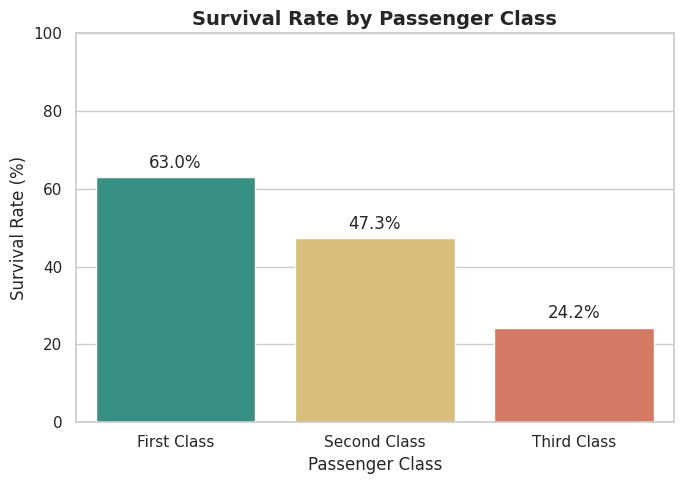

In [9]:
# Calculate survival rates by passenger class
class_survival = (
    train.groupby("Pclass")["Survived"]
    .mean()
    .mul(100)
    .reindex([1, 2, 3])
)

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    x=class_survival.index.astype(str),
    y=class_survival.values,
    hue=class_survival.index.astype(str),
    palette=["#2A9D8F", "#E9C46A", "#E76F51"],
    legend=False,
    ax=ax
)

ax.set_title(
    "Survival Rate by Passenger Class",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["First Class", "Second Class", "Third Class"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

#### Visualization Insights — Survival Rate by Passenger Class

- First-class passengers had the highest survival rate (62.96%), followed by second-class passengers (47.28%) and third-class passengers (24.24%).
- The survival rate of first-class passengers was approximately 2.60 times that of third-class passengers.
- The consistent decline in survival rates across passenger classes suggests a strong association between ticket class and survival outcomes.

**Modeling Implication:** `Pclass` should be retained as a potentially important predictor. Its interaction with `Sex` should also be examined to capture differences in survival patterns across passenger groups.

### 2.3 Survival Rate by Sex and Passenger Class

In [10]:
survival_sex_class = (
    train.groupby(["Pclass", "Sex"])["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival_Rate"
    })
)

survival_sex_class["Survival_Rate"] *= 100

display(survival_sex_class.round(2))

Passengers  Survivors  Survival_Rate
Pclass Sex                                         
1      female          94         91          96.81
       male           122         45          36.89
2      female          76         70          92.11
       male           108         17          15.74
3      female         144         72          50.00
       male           347         47          13.54

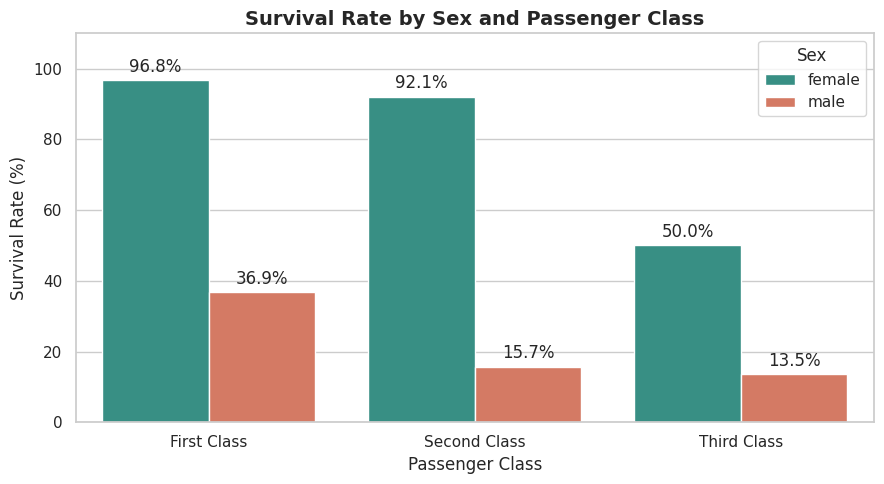

In [11]:
# Calculate survival rates by sex and class
sex_class_survival = (
    train.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .mul(100)
    .reset_index(name="SurvivalRate")
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=sex_class_survival,
    x="Pclass",
    y="SurvivalRate",
    hue="Sex",
    hue_order=["female", "male"],
    palette={
        "female": "#2A9D8F",
        "male": "#E76F51"
    },
    ax=ax
)

ax.set_title(
    "Survival Rate by Sex and Passenger Class",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 110)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(
    ["First Class", "Second Class", "Third Class"]
)

ax.legend(title="Sex")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

#### Visualization Insights — Sex × Passenger Class

- Female passengers consistently had higher survival rates than male passengers across all three passenger classes.
- First-class females had the highest survival rate (96.81%), while third-class males had the lowest (13.54%).
- Third-class females (50.00%) had a higher survival rate than first-class males (36.89%).
- The gender-related survival gap varied across passenger classes, suggesting a potential interaction between `Sex` and `Pclass`.

**Modeling Implication:** The observed patterns support evaluating a `SexPclass` interaction feature. This feature improved Logistic Regression mean cross-validation accuracy from 80.62% to 81.32% in our earlier experiments.

#### Key Insights — Survival Rate by Sex and Passenger Class

- Female passengers consistently exhibited higher survival rates than male passengers across all three passenger classes.
- First-class and second-class female passengers had exceptionally high survival rates of 96.81% and 92.11%, respectively.
- Third-class female passengers (50.00%) had a higher survival rate than first-class male passengers (36.89%).
- Passenger class was associated with survival outcomes within both gender groups, although the magnitude of the differences varied.
- These findings suggest that `Sex` and `Pclass` are potentially valuable predictors, and their interaction should be evaluated during feature engineering.

**Modeling Implication:** Consider testing a combined `Sex × Pclass` feature and evaluating its contribution through cross-validation.

### 2.4 Survival Rate by Age

In [12]:
import pandas as pd

age_df = train.dropna(subset=["Age"]).copy()

age_df["AgeGroup"] = pd.cut(
    age_df["Age"],
    bins=[0, 12, 18, 35, 60, float("inf")],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"],
    include_lowest=True
)

survival_by_age = (
    age_df.groupby("AgeGroup", observed=True)["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival_Rate"
    })
)

survival_by_age["Survival_Rate"] *= 100

display(survival_by_age.round(2))

,Passengers,Survivors,Survival_Rate
AgeGroup,,,
Child,69,40,57.97
Teen,70,30,42.86
Young Adult,358,137,38.27
Adult,195,78,40.00
Senior,22,5,22.73


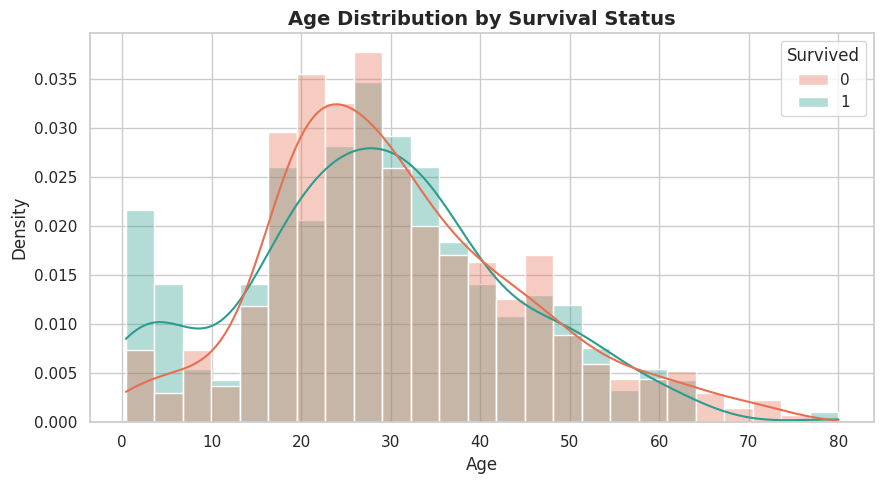

In [13]:
# Prepare age data
age_plot = train.dropna(subset=["Age"]).copy()

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=age_plot,
    x="Age",
    hue="Survived",
    hue_order=[0, 1],
    bins=25,
    stat="density",
    common_norm=False,
    kde=True,
    palette={
        0: "#E76F51",
        1: "#2A9D8F"
    },
    alpha=0.35,
    ax=ax
)

ax.set_title(
    "Age Distribution by Survival Status",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Age")
ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

#### Visualization Insights — Age Distribution

- Both survivors and non-survivors were concentrated primarily in the young-adult age range, particularly between approximately 20 and 35 years.
- Very young children appeared relatively more represented among survivors than non-survivors.
- The substantial overlap between the two age distributions suggests that age alone may have limited ability to distinguish survival outcomes.
- The visualization excludes passengers with missing age values and compares normalized age distributions rather than age-specific survival probabilities.

**Modeling Implication:** Retain `Age` as a numerical predictor, handle missing values within the preprocessing pipeline, and investigate potentially nonlinear age-related survival patterns.

In [14]:
# Create a separate dataset for age visualization
age_plot = train.copy()

# Define age groups
age_bins = [0, 12, 18, 35, 60, float("inf")]
age_labels = [
    "Child", "Teen", "Young Adult",
    "Adult", "Senior"
]

age_plot["AgeGroup"] = pd.cut(
    age_plot["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Check age group distribution
print(age_plot["AgeGroup"].value_counts().sort_index())

AgeGroup
Child           69
Teen            70
Young Adult    358
Adult          195
Senior          22
Name: count, dtype: int64


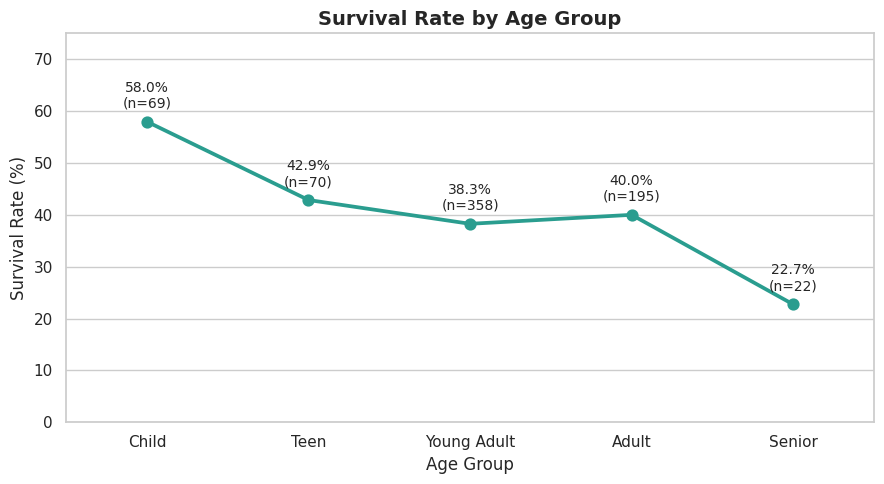

In [15]:
# Calculate survival rates by age group
age_group_survival = (
    age_plot.dropna(subset=["AgeGroup"])
    .groupby("AgeGroup", observed=True)["Survived"]
    .agg(["count", "mean"])
    .reset_index()
)

age_group_survival["SurvivalRate"] = (
    age_group_survival["mean"] * 100
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.pointplot(
    data=age_group_survival,
    x="AgeGroup",
    y="SurvivalRate",
    color="#2A9D8F",
    markers="o",
    linestyles="-",
    errorbar=None,
    ax=ax
)

ax.set_title(
    "Survival Rate by Age Group",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Age Group")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 75)

for i, row in age_group_survival.iterrows():
    ax.annotate(
        f"{row['SurvivalRate']:.1f}%\n(n={int(row['count'])})",
        (i, row["SurvivalRate"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

#### Visualization Insights — Survival Rate by Age Group

- Children had the highest observed survival rate (57.97%), while seniors had the lowest (22.73%).
- Survival rates generally decreased across older age groups, although the pattern was not strictly monotonic.
- Young adults (38.27%) and adults (40.00%) showed similar survival rates.
- The senior group contained only 22 passengers, so its estimated survival rate should be interpreted cautiously.

**Modeling Implication:** Age may have a nonlinear relationship with survival. Age-based features could be explored in future experiments, but their predictive value should be validated rather than assumed.

### 2.5 Survival Rate by Family Size

In [16]:
family_df = train.copy()

# Create family size feature
family_df["FamilySize"] = (
    family_df["SibSp"] + family_df["Parch"] + 1
)

# Calculate survival statistics
survival_by_family = (
    family_df.groupby("FamilySize")["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival_Rate"
    })
)

survival_by_family["Survival_Rate"] *= 100

display(survival_by_family.round(2))

,Passengers,Survivors,Survival_Rate
FamilySize,,,
1,537,163,30.35
2,161,89,55.28
3,102,59,57.84
4,29,21,72.41
5,15,3,20.00
6,22,3,13.64
7,12,4,33.33
8,6,0,0.00
11,7,0,0.00


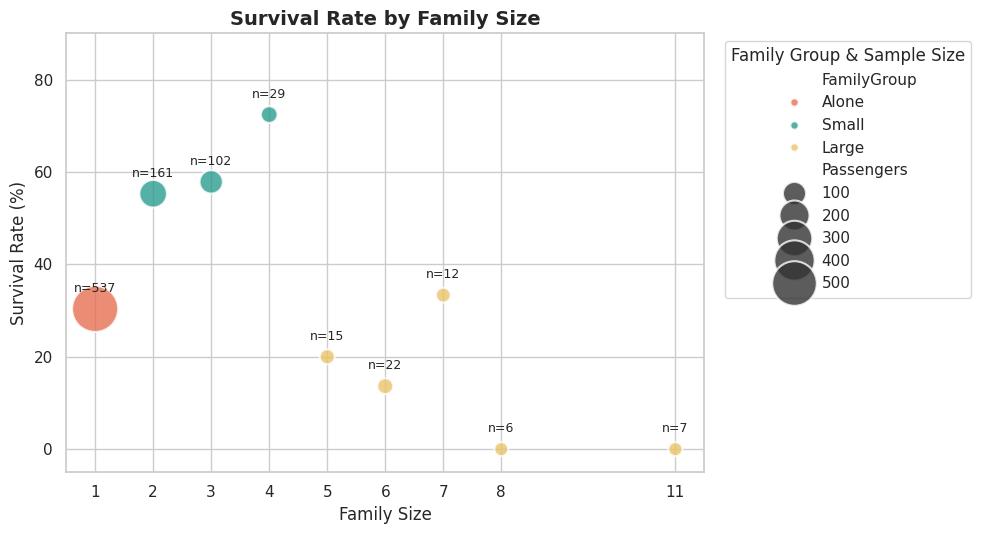

In [17]:
# Prepare family size data
family_plot = train.copy()

family_plot["FamilySize"] = (
    family_plot["SibSp"] + family_plot["Parch"] + 1
)

family_summary = (
    family_plot.groupby("FamilySize")["Survived"]
    .agg(Passengers="count", SurvivalRate="mean")
    .reset_index()
)

family_summary["SurvivalRate"] *= 100

# Categorize family sizes
family_summary["FamilyGroup"] = pd.cut(
    family_summary["FamilySize"],
    bins=[0, 1, 4, float("inf")],
    labels=["Alone", "Small", "Large"]
)

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.scatterplot(
    data=family_summary,
    x="FamilySize",
    y="SurvivalRate",
    size="Passengers",
    sizes=(100, 1100),
    hue="FamilyGroup",
    palette={
        "Alone": "#E76F51",
        "Small": "#2A9D8F",
        "Large": "#E9C46A"
    },
    alpha=0.8,
    edgecolor="white",
    linewidth=1.5,
    ax=ax
)

# Add labels for passenger counts
for _, row in family_summary.iterrows():
    ax.annotate(
        f"n={int(row['Passengers'])}",
        (row["FamilySize"], row["SurvivalRate"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Survival Rate by Family Size",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Family Size")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(-5, 90)
ax.set_xticks(sorted(family_summary["FamilySize"].unique()))

ax.legend(
    title="Family Group & Sample Size",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#### Visualization Insights — Family Size

- Passengers traveling alone represented the largest group (537 passengers) and had a relatively low survival rate of 30.35%.
- Small families of 2–4 members generally exhibited higher survival rates, ranging from 55.28% to 72.41%.
- Larger families tended to have lower survival rates, although several categories contained very few passengers.
- The relationship between family size and survival was nonlinear, highlighting the limitations of treating family size as a purely continuous predictor.

**Modeling Implication:** These patterns motivated the `FamilyGroup` feature, which increased Logistic Regression mean cross-validation accuracy from 79.63% to 80.62% in our experiments.

In [18]:
# Create FamilyGroup for visualization
family_group_plot = train.copy()

family_size = (
    family_group_plot["SibSp"] +
    family_group_plot["Parch"] + 1
)

family_group_plot["FamilyGroup"] = pd.cut(
    family_size,
    bins=[0, 1, 4, float("inf")],
    labels=["Alone", "Small", "Large"]
)

family_group_summary = (
    family_group_plot
    .groupby("FamilyGroup", observed=True)["Survived"]
    .agg(Passengers="count", SurvivalRate="mean")
    .reset_index()
)

family_group_summary["SurvivalRate"] *= 100

display(family_group_summary)

,FamilyGroup,Passengers,SurvivalRate
0,Alone,537,30.353818
1,Small,292,57.876712
2,Large,62,16.129032


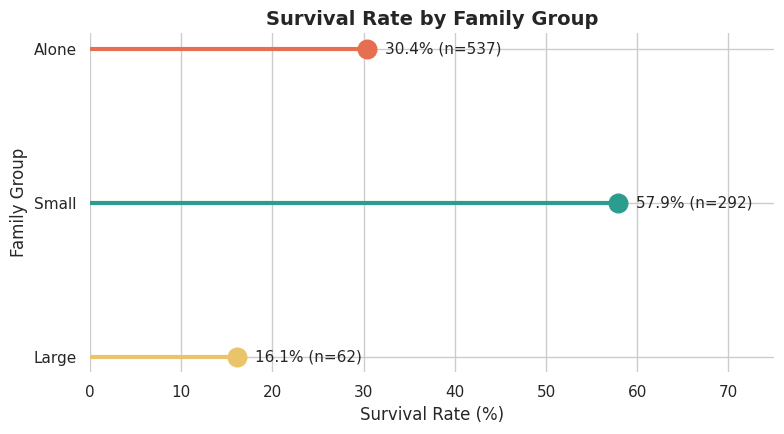

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))

colors = ["#E76F51", "#2A9D8F", "#E9C46A"]

for i, row in family_group_summary.iterrows():
    rate = row["SurvivalRate"]

    ax.hlines(
        y=i, xmin=0, xmax=rate,
        color=colors[i], linewidth=3
    )

    ax.scatter(
        rate, i,
        s=180, color=colors[i],
        zorder=3
    )

    ax.text(
        rate + 2, i,
        f"{rate:.1f}% (n={int(row['Passengers'])})",
        va="center", fontsize=11
    )

ax.set_yticks(range(len(family_group_summary)))
ax.set_yticklabels(family_group_summary["FamilyGroup"])
ax.invert_yaxis()

ax.set_xlim(0, 75)
ax.set_xlabel("Survival Rate (%)")
ax.set_ylabel("Family Group")
ax.set_title(
    "Survival Rate by Family Group",
    fontsize=14,
    fontweight="bold"
)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

#### Visualization Insights — Family Group

- Passengers traveling in small families (2–4 members) had the highest survival rate (57.88%).
- Passengers traveling alone had a survival rate of 30.35%, while those in large families (5+ members) had the lowest rate (16.13%).
- The differences suggest a nonlinear relationship between family size and survival outcomes.
- The large-family group contained only 62 passengers, so its estimated survival rate should be interpreted with some caution.

**Modeling Implication:** The categorical `FamilyGroup` feature captures survival patterns that may not be adequately represented by a single continuous family-size predictor.

### 2.6 Survival Rate by Fare

In [20]:
fare_df = train.copy()

# Divide fares into quartiles
fare_df["FareGroup"] = pd.qcut(
    fare_df["Fare"],
    q=4,
    duplicates="drop"
)

survival_by_fare = (
    fare_df.groupby("FareGroup", observed=True)["Survived"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Passengers",
        "sum": "Survivors",
        "mean": "Survival_Rate"
    })
)

survival_by_fare["Survival_Rate"] *= 100

display(survival_by_fare.round(2))

,Passengers,Survivors,Survival_Rate
FareGroup,,,
"(-0.001, 7.91]",223,44,19.73
"(7.91, 14.454]",224,68,30.36
"(14.454, 31.0]",222,101,45.50
"(31.0, 512.329]",222,129,58.11


#### Key Insights — Survival Rate by Fare

- Survival rates increased consistently across the four fare quartiles, from 19.73% in the lowest quartile to 58.11% in the highest.
- Passengers in the highest fare quartile had approximately 2.95 times the survival rate of those in the lowest quartile.
- This positive association suggests that `Fare` may be a useful predictor of survival.
- However, `Fare` may be strongly associated with `Pclass`, so its independent predictive contribution remains uncertain.
- The wide range of fares in the highest quartile suggests that further examination of skewness and extreme values may be useful.

**Modeling Implication:** Compare raw `Fare` with a log-transformed version and evaluate its contribution alongside `Pclass` using cross-validation.

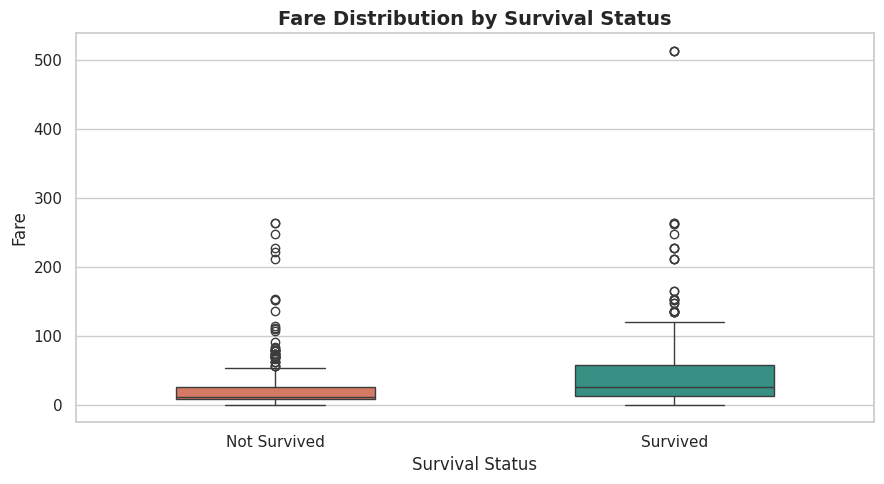

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=train,
    x="Survived",
    y="Fare",
    hue="Survived",
    palette={
        0: "#E76F51",
        1: "#2A9D8F"
    },
    legend=False,
    width=0.5,
    ax=ax
)

ax.set_title(
    "Fare Distribution by Survival Status",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Survival Status")
ax.set_ylabel("Fare")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not Survived", "Survived"])

plt.tight_layout()
plt.show()

#### Visualization Insights — Fare Distribution

- Survivors generally paid higher fares than non-survivors, as indicated by their higher median fare.
- The survivor group exhibited a wider interquartile range (IQR), suggesting greater variability in fares among the middle 50% of observations.
- Both groups contained numerous high-fare outliers, reflecting the strongly right-skewed nature of the fare distribution.
- The observed relationship between fare and survival may be influenced by passenger class and should not be interpreted as causal.

**Modeling Implication:** Retain `Fare` as a potentially informative numerical feature. Consider evaluating a logarithmic transformation in future experiments to reduce skewness and the influence of extreme values.

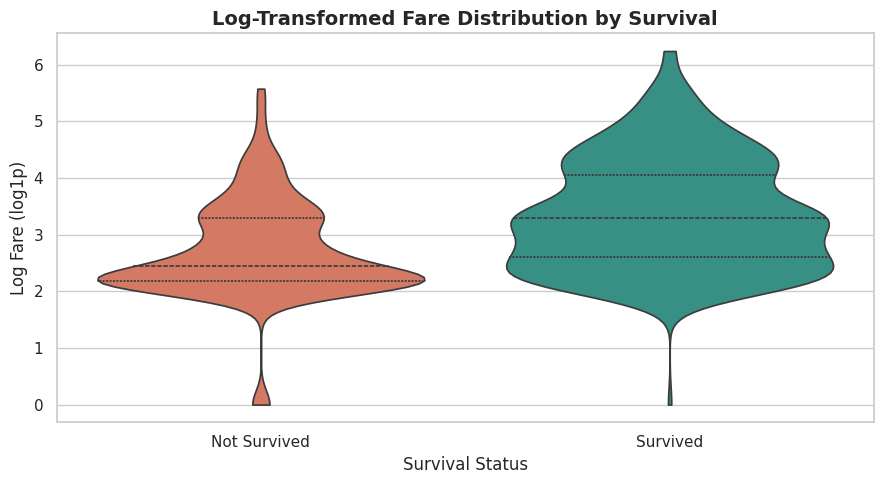

In [22]:
# Create a separate dataset for visualization
fare_plot = train.copy()

# Apply log1p transformation
fare_plot["LogFare"] = np.log1p(fare_plot["Fare"])

fig, ax = plt.subplots(figsize=(9, 5))

sns.violinplot(
    data=fare_plot,
    x="Survived",
    y="LogFare",
    hue="Survived",
    palette={
        0: "#E76F51",
        1: "#2A9D8F"
    },
    legend=False,
    inner="quartile",
    cut=0,
    ax=ax
)

ax.set_title(
    "Log-Transformed Fare Distribution by Survival",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Survival Status")
ax.set_ylabel("Log Fare (log1p)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not Survived", "Survived"])

plt.tight_layout()
plt.show()

#### Visualization Insights — Log-Transformed Fare

- Survivors generally exhibited higher log-transformed fares than non-survivors, as reflected by their higher median.
- The survivor group showed a broader distribution across moderate and high fare values.
- Despite these differences, the two distributions overlapped substantially, indicating that fare alone is insufficient to distinguish survival outcomes.
- Applying `log1p(Fare)` compressed extreme values and made the underlying distribution easier to visualize without removing observations.

**Modeling Implication:** A logarithmic transformation of `Fare` may be worth evaluating in future experiments, particularly for models sensitive to feature distributions. Any improvement should be confirmed through cross-validation.

In [23]:
# Create fare quartiles
fare_quartile_plot = train.copy()

fare_quartile_plot["FareQuartile"] = pd.qcut(
    fare_quartile_plot["Fare"],
    q=4,
    labels=["Q1 - Lowest", "Q2", "Q3", "Q4 - Highest"]
)

fare_quartile_summary = (
    fare_quartile_plot
    .groupby("FareQuartile", observed=True)["Survived"]
    .agg(Passengers="count", SurvivalRate="mean")
)

fare_quartile_summary["SurvivalRate"] *= 100

display(fare_quartile_summary.round(2))

,Passengers,SurvivalRate
FareQuartile,,
Q1 - Lowest,223,19.73
Q2,224,30.36
Q3,222,45.50
Q4 - Highest,222,58.11


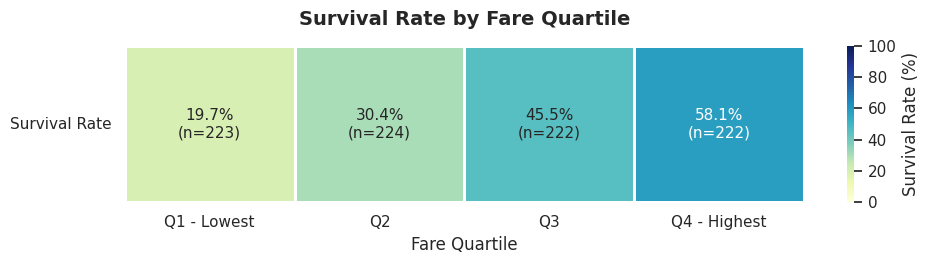

In [24]:
# Prepare heatmap values
heatmap_data = fare_quartile_summary[["SurvivalRate"]].T

# Create annotations with rates and sample sizes
annotations = [
    [
        f"{row['SurvivalRate']:.1f}%\n(n={int(row['Passengers'])})"
        for _, row in fare_quartile_summary.iterrows()
    ]
]

fig, ax = plt.subplots(figsize=(10, 2.8))

sns.heatmap(
    heatmap_data,
    annot=annotations,
    fmt="",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=2,
    linecolor="white",
    cbar_kws={"label": "Survival Rate (%)"},
    annot_kws={"fontsize": 11},
    ax=ax
)

ax.set_title(
    "Survival Rate by Fare Quartile",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Fare Quartile")
ax.set_ylabel("")
ax.set_yticklabels(["Survival Rate"], rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

#### Visualization Insights — Fare Quartiles

- Survival rates increased consistently across fare quartiles, from 19.73% in the lowest quartile to 58.11% in the highest quartile.
- The highest-fare group had a survival rate approximately 2.94 times that of the lowest-fare group.
- Each quartile contained approximately the same number of passengers, making the observed differences easier to compare.
- The association between fare and survival may partly reflect differences in passenger class rather than an independent effect of ticket price.

**Modeling Implication:** `Fare` is a potentially useful predictor, but its relationship with `Pclass` should be considered when interpreting model results.

## 3. Data Preprocessing & Baseline Modeling

### 3.1 Train–Validation Split

We split the training dataset into training (80%) and
validation (20%) subsets using stratified sampling
to preserve the target class distribution.

In [25]:
from sklearn.model_selection import train_test_split

# Select baseline features
features = [
    "Pclass", "Sex", "Age",
    "SibSp", "Parch", "Fare", "Embarked"
]

X = train[features]
y = train["Survived"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

X_train: (712, 7)
X_val: (179, 7)

Training target distribution:
Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Validation target distribution:
Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


### 3.2 Data Preprocessing Pipeline

A preprocessing pipeline is used to handle missing values,
encode categorical features, and scale numerical features.

All preprocessing parameters will be learned exclusively
from the training data to prevent data leakage.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define feature groups
numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = [
    "Sex", "Embarked"
]

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'Embarked'])])


### 3.3 Logistic Regression Baseline

Logistic Regression is used as the initial classification
model to predict passenger survival.

The model combines preprocessing and classification in a
single pipeline to prevent data leakage.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Build baseline pipeline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
baseline_model.fit(X_train, y_train)

# Predict on validation data
y_pred = baseline_model.predict(X_val)

print("Model training completed!")
print("Predictions:", y_pred[:10])

Model training completed!
Predictions: [0 0 0 0 1 0 1 0 0 0]


### 3.4 Baseline Model Evaluation

The baseline model is evaluated using Accuracy, Precision,
Recall, F1-score, and a Confusion Matrix.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
print("Accuracy :", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred), 4))
print("Recall   :", round(recall_score(y_val, y_pred), 4))
print("F1-score :", round(f1_score(y_val, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy : 0.8045
Precision: 0.7931
Recall   : 0.6667
F1-score : 0.7244

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Confusion Matrix:
[[98 12]
 [23 46]]


#### Baseline Model Evaluation — Key Insights

- The Logistic Regression baseline achieved **80.45% validation accuracy**, correctly classifying 144 out of 179 passengers.
- The model substantially outperformed a majority-class baseline, which would achieve approximately 61.45% accuracy.
- Precision, Recall, and F1-score for the survival class were 79.31%, 66.67%, and 72.44%, respectively.
- The confusion matrix revealed 12 false positives and 23 false negatives, indicating that the model missed one-third of actual survivors.
- The model performed better at identifying non-survivors (89% recall) than survivors (67% recall).

**Modeling Implication:** This baseline provides a useful reference for evaluating feature engineering and alternative algorithms. Future improvements should prioritize reliable validation accuracy rather than training accuracy alone.

### 3.5 Stratified K-Fold Cross-Validation

Five-fold stratified cross-validation is used to
evaluate the stability and generalization performance
of the Logistic Regression baseline.

In [29]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("CV Accuracy Scores:", cv_scores.round(4))
print("Mean CV Accuracy  :", round(cv_scores.mean(), 4))
print("Std CV Accuracy   :", round(cv_scores.std(), 4))

CV Accuracy Scores: [0.7972 0.7972 0.8099 0.7465 0.831 ]
Mean CV Accuracy  : 0.7963
Std CV Accuracy   : 0.0278


#### Cross-Validation — Key Insights

- The Logistic Regression baseline achieved a mean 5-fold cross-validation accuracy of **79.63%**, with a standard deviation of **2.78 percentage points**.
- Accuracy ranged from 74.65% to 83.10% across the five folds, indicating some sensitivity to the validation split.
- The holdout validation accuracy of 80.45% was close to the cross-validation mean, providing additional confidence in the baseline's estimated performance.
- These results establish a reference point for evaluating future feature engineering and model improvements.

**Modeling Implication:** Subsequent experiments will use the same stratified cross-validation strategy to compare candidate models consistently. The holdout validation set will remain separate from model selection.

## 4. Feature Engineering & Model Improvement

### 4.1 Experiment 1 — FamilySize

We introduce FamilySize as a new feature derived from
SibSp and Parch to evaluate whether family composition
improves survival prediction.

In [30]:
# Create copies to preserve the original datasets
X_train_fs = X_train.copy()
X_val_fs = X_val.copy()

# Engineer FamilySize
X_train_fs["FamilySize"] = (
    X_train_fs["SibSp"] + X_train_fs["Parch"] + 1
)

X_val_fs["FamilySize"] = (
    X_val_fs["SibSp"] + X_val_fs["Parch"] + 1
)

print("Training shape:", X_train_fs.shape)
print("Validation shape:", X_val_fs.shape)

display(X_train_fs.head())

Training shape: (712, 8)
Validation shape: (179, 8)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
692,3,male,NaN,0,0,56.4958,S,1
481,2,male,NaN,0,0,0.0000,S,1
527,1,male,NaN,0,0,221.7792,S,1
855,3,female,18.0,0,1,9.3500,S,2
801,2,female,31.0,1,1,26.2500,S,3


In [31]:
# Add FamilySize to numeric features
numeric_features_fs = numeric_features + ["FamilySize"]

preprocessor_fs = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features_fs),
        ("cat", categorical_transformer, categorical_features)
    ]
)

model_fs = Pipeline(steps=[
    ("preprocessor", preprocessor_fs),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [32]:
cv_scores_fs = cross_val_score(
    model_fs,
    X_train_fs,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Baseline CV Accuracy:",
      round(cv_scores.mean(), 4))

print("FamilySize CV Scores:",
      cv_scores_fs.round(4))

print("FamilySize Mean CV:",
      round(cv_scores_fs.mean(), 4))

print("FamilySize Std CV:",
      round(cv_scores_fs.std(), 4))

print("Improvement:",
      round(cv_scores_fs.mean() - cv_scores.mean(), 4))

Baseline CV Accuracy: 0.7963
FamilySize CV Scores: [0.7972 0.7972 0.8099 0.7465 0.831 ]
FamilySize Mean CV: 0.7963
FamilySize Std CV: 0.0278
Improvement: 0.0


#### Experiment 1 — FamilySize

The `FamilySize` feature was created by combining `SibSp` and `Parch`.

**Results:**
- Baseline Mean CV Accuracy: 79.63%
- FamilySize Mean CV Accuracy: 79.63%
- Accuracy Improvement: 0.00 percentage points

Adding `FamilySize` did not improve cross-validation accuracy. Since this feature is a linear combination of two existing predictors, it provides no independent information to the Logistic Regression model.

**Decision:** Do not retain `FamilySize` as an additional numerical feature in the current baseline. Instead, evaluate a categorical representation to capture potential nonlinear relationships.

### 4.2 Experiment 2 — FamilyGroup

We categorize passengers into three family groups:
Alone, Small, and Large.

This experiment evaluates whether a categorical
representation of family size improves prediction
by capturing nonlinear survival patterns.

In [33]:
# Create copies of the original baseline features
X_train_fg = X_train.copy()
X_val_fg = X_val.copy()

def create_family_group(df):
    family_size = df["SibSp"] + df["Parch"] + 1

    return pd.cut(
        family_size,
        bins=[0, 1, 4, float("inf")],
        labels=["Alone", "Small", "Large"]
    )

# Create FamilyGroup feature
X_train_fg["FamilyGroup"] = create_family_group(X_train_fg)
X_val_fg["FamilyGroup"] = create_family_group(X_val_fg)

print("Training shape:", X_train_fg.shape)
print("Validation shape:", X_val_fg.shape)

display(X_train_fg[["SibSp", "Parch", "FamilyGroup"]].head())

Training shape: (712, 8)
Validation shape: (179, 8)


,SibSp,Parch,FamilyGroup
692,0,0,Alone
481,0,0,Alone
527,0,0,Alone
855,0,1,Small
801,1,1,Small


In [34]:
# Add FamilyGroup to categorical features
categorical_features_fg = categorical_features + ["FamilyGroup"]

preprocessor_fg = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features_fg)
    ]
)

model_fg = Pipeline(steps=[
    ("preprocessor", preprocessor_fg),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [35]:
cv_scores_fg = cross_val_score(
    model_fg,
    X_train_fg,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Baseline Mean CV:",
      round(cv_scores.mean(), 4))

print("FamilySize Mean CV:",
      round(cv_scores_fs.mean(), 4))

print("FamilyGroup CV Scores:",
      cv_scores_fg.round(4))

print("FamilyGroup Mean CV:",
      round(cv_scores_fg.mean(), 4))

print("FamilyGroup Std CV:",
      round(cv_scores_fg.std(), 4))

print("Improvement vs Baseline:",
      round(cv_scores_fg.mean() - cv_scores.mean(), 4))

Baseline Mean CV: 0.7963
FamilySize Mean CV: 0.7963
FamilyGroup CV Scores: [0.8252 0.7902 0.8099 0.7746 0.831 ]
FamilyGroup Mean CV: 0.8062
FamilyGroup Std CV: 0.0212
Improvement vs Baseline: 0.0098


#### Experiment 2 — FamilyGroup

The `FamilyGroup` feature categorizes passengers into three groups: Alone (1), Small (2–4), and Large (5+).

**Results:**
- Baseline Mean CV Accuracy: 79.63%
- FamilyGroup Mean CV Accuracy: 80.62%
- Accuracy Improvement: +0.98 percentage points
- CV Standard Deviation decreased from 2.78 to 2.12 percentage points.

Unlike the numerical `FamilySize` feature, the categorical `FamilyGroup` representation improved cross-validation accuracy.

This suggests that modeling nonlinear patterns in family size may be more effective than treating family size as a continuous numerical predictor.

**Decision:** Retain `FamilyGroup` as a promising candidate feature for subsequent experiments. Its improvement remains preliminary and should be verified through further validation.

### 4.3 Experiment 3 — Sex × Pclass Interaction

We introduce an interaction feature combining Sex and Pclass
to capture potential differences in class-related survival
patterns between male and female passengers.

In [36]:
# Start from the FamilyGroup experiment
X_train_inter = X_train_fg.copy()
X_val_inter = X_val_fg.copy()

# Create interaction feature
X_train_inter["SexPclass"] = (
    X_train_inter["Sex"] + "_" +
    X_train_inter["Pclass"].astype(str)
)

X_val_inter["SexPclass"] = (
    X_val_inter["Sex"] + "_" +
    X_val_inter["Pclass"].astype(str)
)

print("Training shape:", X_train_inter.shape)
print("Validation shape:", X_val_inter.shape)

print("\nInteraction categories:")
print(X_train_inter["SexPclass"].value_counts())

Training shape: (712, 9)
Validation shape: (179, 9)

Interaction categories:
SexPclass
male_3      275
female_3    116
male_2       92
male_1       92
female_1     79
female_2     58
Name: count, dtype: int64


In [37]:
# Add interaction to categorical features
categorical_features_inter = (
    categorical_features_fg + ["SexPclass"]
)

preprocessor_inter = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer,
         categorical_features_inter)
    ]
)

model_inter = Pipeline(steps=[
    ("preprocessor", preprocessor_inter),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [38]:
cv_scores_inter = cross_val_score(
    model_inter,
    X_train_inter,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Baseline Mean CV:",
      round(cv_scores.mean(), 4))

print("FamilyGroup Mean CV:",
      round(cv_scores_fg.mean(), 4))

print("Interaction CV Scores:",
      cv_scores_inter.round(4))

print("Interaction Mean CV:",
      round(cv_scores_inter.mean(), 4))

print("Interaction Std CV:",
      round(cv_scores_inter.std(), 4))

print("Improvement vs FamilyGroup:",
      round(cv_scores_inter.mean() - cv_scores_fg.mean(), 4))

Baseline Mean CV: 0.7963
FamilyGroup Mean CV: 0.8062
Interaction CV Scores: [0.8182 0.7972 0.8451 0.7887 0.8169]
Interaction Mean CV: 0.8132
Interaction Std CV: 0.0195
Improvement vs FamilyGroup: 0.007


#### Experiment 3 — Sex × Pclass Interaction

A new categorical feature, `SexPclass`, was created to capture interaction effects between passenger sex and ticket class.

**Results:**
- Baseline Mean CV Accuracy: 79.63%
- FamilyGroup Mean CV Accuracy: 80.62%
- Interaction Mean CV Accuracy: 81.32%
- Improvement over FamilyGroup: +0.70 percentage points
- Total improvement over baseline: +1.69 percentage points

The interaction-enhanced model achieved the highest mean cross-validation accuracy among the Logistic Regression configurations tested so far.

The improvement suggests that allowing class-related survival patterns to differ by sex may provide additional predictive value.

However, performance did not improve in every fold, and the observed gain is relatively small.

**Decision:** Retain the interaction-enhanced Logistic Regression as the current leading candidate and compare it against nonlinear classification algorithms.

### 4.4 Experiment 4 — Random Forest Classifier

We compare Random Forest against the interaction-enhanced
Logistic Regression using the same features and
stratified cross-validation folds.

In [39]:
from sklearn.ensemble import RandomForestClassifier

model_rf = Pipeline(steps=[
    ("preprocessor", preprocessor_inter),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

print(model_rf)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown=

In [40]:
cv_scores_rf = cross_val_score(
    model_rf,
    X_train_inter,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Logistic Regression CV:",
      round(cv_scores_inter.mean(), 4))

print("Random Forest CV Scores:",
      cv_scores_rf.round(4))

print("Random Forest Mean CV:",
      round(cv_scores_rf.mean(), 4))

print("Random Forest Std CV:",
      round(cv_scores_rf.std(), 4))

print("Improvement vs Logistic Regression:",
      round(cv_scores_rf.mean() - cv_scores_inter.mean(), 4))

Logistic Regression CV: 0.8132
Random Forest CV Scores: [0.8322 0.8042 0.838  0.8028 0.8099]
Random Forest Mean CV: 0.8174
Random Forest Std CV: 0.0147
Improvement vs Logistic Regression: 0.0042


#### Experiment 4 — Random Forest Classifier

Random Forest was evaluated using the same engineered features and stratified five-fold cross-validation strategy as the interaction-enhanced Logistic Regression.

**Results:**
- Logistic Regression Mean CV Accuracy: 81.32%
- Random Forest Mean CV Accuracy: 81.74%
- Improvement: +0.42 percentage points
- Random Forest CV Standard Deviation: 1.47 percentage points

Random Forest achieved a slightly higher mean cross-validation accuracy and lower fold-to-fold variability than Logistic Regression.

However, the improvement was modest, and Random Forest did not outperform Logistic Regression on every fold.

**Decision:** Retain both models as candidates. Conduct a final holdout evaluation before selecting the model for Kaggle submission.

### 4.5 Final Holdout Evaluation

The two leading models are evaluated on the untouched
holdout validation set to assess generalization
performance beyond cross-validation.

In [41]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.base import clone

# Fit both models on the full training split
final_lr = clone(model_inter)
final_rf = clone(model_rf)

final_lr.fit(X_train_inter, y_train)
final_rf.fit(X_train_inter, y_train)

# Predict on the untouched holdout set
y_pred_lr = final_lr.predict(X_val_inter)
y_pred_rf = final_rf.predict(X_val_inter)

# Compare accuracy
lr_accuracy = accuracy_score(y_val, y_pred_lr)
rf_accuracy = accuracy_score(y_val, y_pred_rf)

print("Logistic Regression Holdout Accuracy:",
      round(lr_accuracy, 4))

print("Random Forest Holdout Accuracy:",
      round(rf_accuracy, 4))

print("\nLogistic Regression Report:")
print(classification_report(y_val, y_pred_lr))

print("\nRandom Forest Report:")
print(classification_report(y_val, y_pred_rf))

Logistic Regression Holdout Accuracy: 0.8101
Random Forest Holdout Accuracy: 0.8045

Logistic Regression Report:
              precision    recall  f1-score   support

           0       0.79      0.94      0.86       110
           1       0.86      0.61      0.71        69

    accuracy                           0.81       179
   macro avg       0.82      0.77      0.79       179
weighted avg       0.82      0.81      0.80       179


Random Forest Report:
              precision    recall  f1-score   support

           0       0.79      0.93      0.85       110
           1       0.84      0.61      0.71        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



#### Final Holdout Evaluation — Key Insights

The two leading models were evaluated on the reserved holdout validation set.

**Results:**
- Logistic Regression Holdout Accuracy: 81.01%
- Random Forest Holdout Accuracy: 80.45%
- Logistic Regression Mean CV Accuracy: 81.32%
- Random Forest Mean CV Accuracy: 81.74%

Both models achieved similar holdout performance, with Logistic Regression correctly predicting one additional passenger.

The small difference does not establish a statistically meaningful advantage for either model.

**Decision:** Select the interaction-enhanced Logistic Regression as the first Kaggle submission candidate because of its competitive performance, simplicity, and interpretability. Retain Random Forest as an alternative for future experiments.

### Confusion Matrix Visualization

In [42]:
# Check available model-related variables
model_vars = [
    name for name in globals()
    if any(keyword in name.lower()
           for keyword in ["logistic", "forest", "pred", "model"])
]

print(sorted(model_vars))

['LogisticRegression', 'RandomForestClassifier', 'baseline_model', 'model_fg', 'model_fs', 'model_inter', 'model_rf', 'y_pred', 'y_pred_lr', 'y_pred_rf']


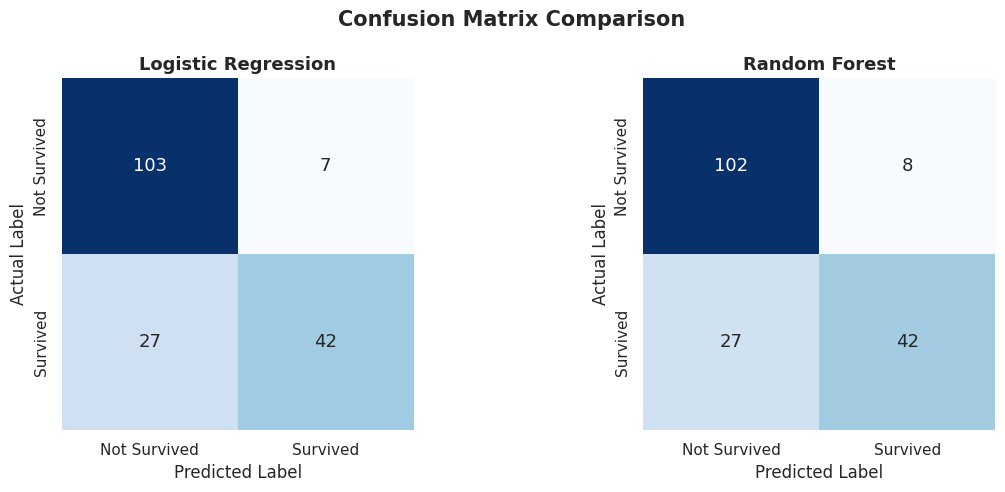

In [43]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrices
cm_lr = confusion_matrix(y_val, y_pred_lr, labels=[0, 1])
cm_rf = confusion_matrix(y_val, y_pred_rf, labels=[0, 1])

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Logistic Regression", cm_lr),
    ("Random Forest", cm_rf)
]

for ax, (name, cm) in zip(axes, models):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=["Not Survived", "Survived"],
        yticklabels=["Not Survived", "Survived"],
        annot_kws={"fontsize": 13},
        ax=ax
    )

    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Visualization Insights — Confusion Matrix Comparison

- Logistic Regression correctly classified 145 out of 179 validation passengers, compared with 144 for Random Forest.
- Both models correctly identified 42 survivors but failed to identify 27 actual survivors, resulting in a survivor recall of approximately 60.9%.
- Logistic Regression produced one fewer false positive than Random Forest, giving it a slightly higher holdout accuracy and precision for the survivor class.
- Both models performed better at identifying non-survivors than survivors.

**Modeling Implication:** The models achieve reasonable overall accuracy but have relatively limited recall for survivors. The small performance difference does not establish a clear winner, so cross-validation results should also be considered when selecting the final model.

### Model Performance Comparison

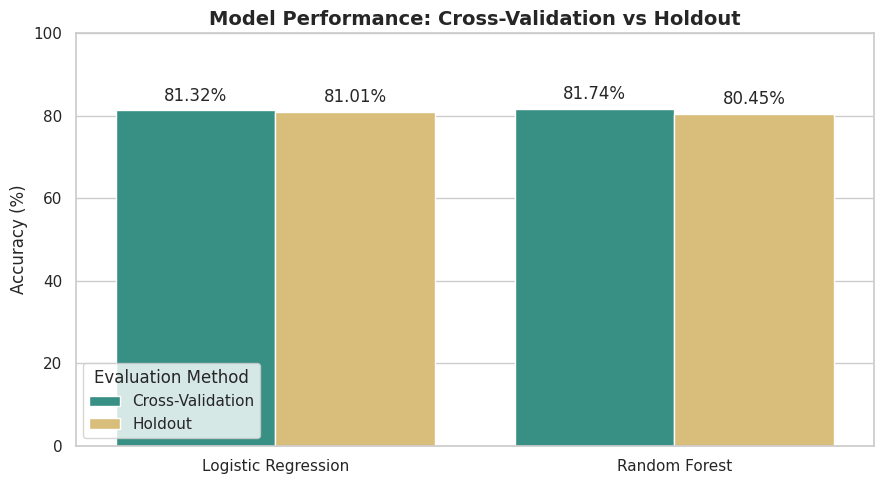

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Model evaluation results
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Cross-Validation": [
        cv_scores_inter.mean(),
        cv_scores_rf.mean()
    ],
    "Holdout": [
        lr_accuracy,
        rf_accuracy
    ]
})

# Reshape for visualization
comparison_long = comparison.melt(
    id_vars="Model",
    var_name="Evaluation Method",
    value_name="Accuracy"
)

comparison_long["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Accuracy",
    hue="Evaluation Method",
    palette=["#2A9D8F", "#E9C46A"],
    ax=ax
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

ax.set_title(
    "Model Performance: Cross-Validation vs Holdout",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.legend(title="Evaluation Method")

plt.tight_layout()
plt.show()

#### Visualization Insights — Model Performance Comparison

- Random Forest achieved a slightly higher mean cross-validation accuracy (81.74%) than Logistic Regression (81.32%).
- Logistic Regression performed marginally better on the holdout validation set, achieving 81.01% accuracy compared with 80.45% for Random Forest.
- Both models demonstrated relatively consistent performance across cross-validation and holdout evaluation, with accuracy scores ranging from approximately 80% to 82%.
- The differences between the two models were small and do not provide conclusive evidence that one consistently outperforms the other.

**Model Selection:** Both models are competitive candidates. Model selection should consider cross-validation stability, interpretability, and performance on unseen data rather than relying on a single accuracy score.

## 5. Kaggle Submission

### 5.1 Final Model Training

The selected Logistic Regression model is retrained
on the complete labeled training dataset before
generating predictions for the Kaggle test set.

In [45]:
from sklearn.base import clone

# Prepare the full training and competition test sets
X_full = train[features].copy()
X_test = test[features].copy()

y_full = train["Survived"]

def add_engineered_features(df):
    df = df.copy()

    family_size = df["SibSp"] + df["Parch"] + 1

    df["FamilyGroup"] = pd.cut(
        family_size,
        bins=[0, 1, 4, float("inf")],
        labels=["Alone", "Small", "Large"]
    )

    df["SexPclass"] = (
        df["Sex"] + "_" + df["Pclass"].astype(str)
    )

    return df

X_full = add_engineered_features(X_full)
X_test = add_engineered_features(X_test)

print("Full training shape:", X_full.shape)
print("Test shape:", X_test.shape)

display(X_test.head())

Full training shape: (891, 9)
Test shape: (418, 9)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilyGroup,SexPclass
0,3,male,34.5,0,0,7.8292,Q,Alone,male_3
1,3,female,47.0,1,0,7.0000,S,Small,female_3
2,2,male,62.0,0,0,9.6875,Q,Alone,male_2
3,3,male,27.0,0,0,8.6625,S,Alone,male_3
4,3,female,22.0,1,1,12.2875,S,Small,female_3


In [46]:
# Clone the selected model
final_model = clone(model_inter)

# Retrain using all labeled passengers
final_model.fit(X_full, y_full)

# Generate predictions for the competition test set
test_predictions = final_model.predict(X_test)

print("Number of predictions:", len(test_predictions))
print("Prediction distribution:")
print(pd.Series(test_predictions).value_counts())

Number of predictions: 418
Prediction distribution:
0    278
1    140
Name: count, dtype: int64


In [47]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions.astype(int)
})

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("Submission shape:", submission.shape)
print("Missing values:")
print(submission.isnull().sum())

display(submission.head())

Submission shape: (418, 2)
Missing values:
PassengerId    0
Survived       0
dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [48]:
assert submission.shape == (418, 2)
assert submission.columns.tolist() == [
    "PassengerId", "Survived"
]
assert submission["PassengerId"].equals(
    test["PassengerId"]
)
assert submission["Survived"].isin([0, 1]).all()
assert not submission.isnull().any().any()

print("Submission validation passed!")

Submission validation passed!


## Conclusion & Future Improvements

### 1. Key Findings from Exploratory Data Analysis

The exploratory analysis revealed several important patterns associated with passenger survival:

- **Sex:** Female passengers had a substantially higher survival rate (74.20%) than male passengers (18.89%).
- **Passenger Class:** First-class passengers had the highest survival rate (62.96%), followed by second-class (47.28%) and third-class passengers (24.24%).
- **Age:** Children exhibited relatively high survival rates, although age-related findings were limited by missing values.
- **Family Size:** Passengers traveling in small families had higher survival rates than those traveling alone or in large families.
- **Fare:** Survival rates increased across fare quartiles, suggesting an association between ticket price and survival outcomes.

These findings highlight the importance of demographic, socioeconomic, and family-related characteristics in predicting passenger survival. However, the observed relationships should not be interpreted as causal.

### 2. Feature Engineering

Several features were explored to capture additional information from the original dataset:

- `FamilySize`: Total number of family members traveling together, including the passenger.
- `FamilyGroup`: Categorization of passengers into alone, small-family, and large-family groups.
- `SexPclass`: Interaction feature combining sex and passenger class.

Cross-validation results suggested that the categorical family-group and sex–class interaction features provided useful predictive information.

### 3. Model Development and Evaluation

Two classification algorithms were evaluated using stratified cross-validation and a holdout validation set.

| Model | Mean CV Accuracy | Holdout Accuracy |
|---|---:|---:|
| Logistic Regression | 81.32% | 81.01% |
| Random Forest | 81.74% | 80.45% |

Random Forest achieved a slightly higher cross-validation accuracy, while Logistic Regression performed marginally better on the holdout set.

Both models demonstrated comparable performance, with no conclusive evidence that one consistently outperformed the other.

Confusion matrix analysis also revealed that both models identified non-survivors more effectively than survivors, indicating room for improvement in survivor recall.

### 4. Future Improvements

Potential directions for further experimentation include:

1. **Advanced Feature Engineering:** Extract passenger titles from names, investigate ticket-group information, and explore cabin-related features.
2. **Hyperparameter Optimization:** Apply RandomizedSearchCV or GridSearchCV to systematically tune model parameters.
3. **Alternative Algorithms:** Evaluate Gradient Boosting, XGBoost, CatBoost, or LightGBM.
4. **Feature Transformation:** Experiment with logarithmic fare transformation and alternative age-imputation strategies.
5. **Robust Validation:** Compare model performance across repeated stratified cross-validation splits to assess stability.

### 5. Final Remarks

This project demonstrates an end-to-end machine learning workflow, including data exploration, preprocessing, feature engineering, model training, validation, and prediction generation.

The primary objective was not only to achieve competitive prediction accuracy but also to develop a systematic, interpretable, and reproducible approach to solving a classification problem.

Future iterations will focus on improving generalization performance through more advanced feature engineering and systematic experimentation.